In [ ]:
# ============================================================
# CELL 1 — Imports & Load
# ============================================================
# All the Necessary Libraries For Data Analysis
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.figure_factory as ff
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import MinMaxScaler
%matplotlib inline

df = pd.read_csv(r"E:\DOCUMENTS\UNIVERSITÄT STUTTGART\SEMESTER COURSES\7. WiSe 2025-26\RP\Datasets\predictive_maintenance_v03.csv") #The path to the dataset
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['machine_id', 'timestamp']).reset_index(drop=True)

print("Shape:", df.shape)
print(df.dtypes)
print(df.head(3))

Shape: (24042, 13)
timestamp                  datetime64[ns]
machine_id                          int64
machine_type                       object
vibration_rms                     float64
temperature_motor                 float64
current_phase_avg                 float64
pressure_level                    float64
rpm                               float64
operating_mode                     object
hours_since_maintenance           float64
rul_hours                         float64
failure_type                       object
estimated_repair_cost               int64
dtype: object
            timestamp  machine_id machine_type  vibration_rms  \
0 2024-01-01 00:00:00           1          CNC           0.81   
1 2024-01-01 00:03:00           1          CNC           0.75   
2 2024-01-01 00:21:00           1          CNC           0.71   

   temperature_motor  current_phase_avg  pressure_level    rpm operating_mode  \
0              49.51                5.1            23.6  860.9           idle  

                         Missing  Pct%
timestamp                      0  0.00
machine_id                     0  0.00
machine_type                   0  0.00
vibration_rms               1000  4.16
temperature_motor            834  3.47
current_phase_avg            731  3.04
pressure_level               924  3.84
rpm                          533  2.22
operating_mode                 0  0.00
hours_since_maintenance        0  0.00
rul_hours                      0  0.00
failure_type                   0  0.00
estimated_repair_cost          0  0.00


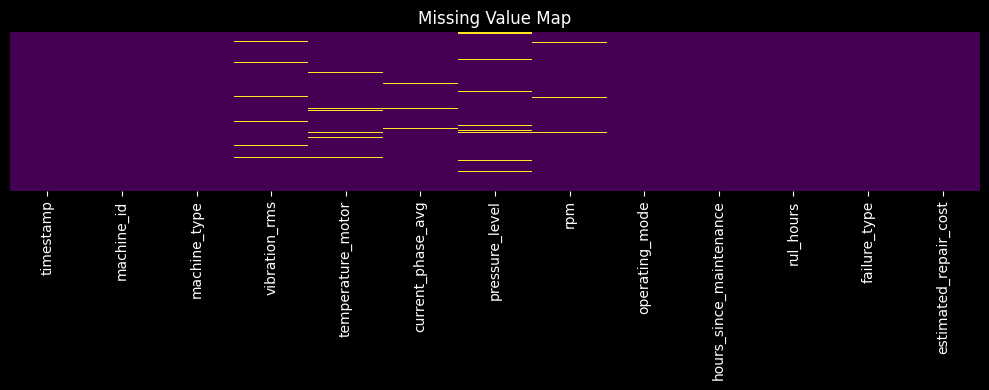

In [2]:
# CELL 2 — Missing Values
# ============================================================
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({'Missing': missing, 'Pct%': missing_pct}))

plt.figure(figsize=(10,4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Missing Value Map")
plt.tight_layout()
plt.show()

failure_type
none              20482
bearing            1117
motor_overheat     1060
hydraulic           728
electrical          655
Name: count, dtype: int64

Class imbalance: 85.2% are no-failure


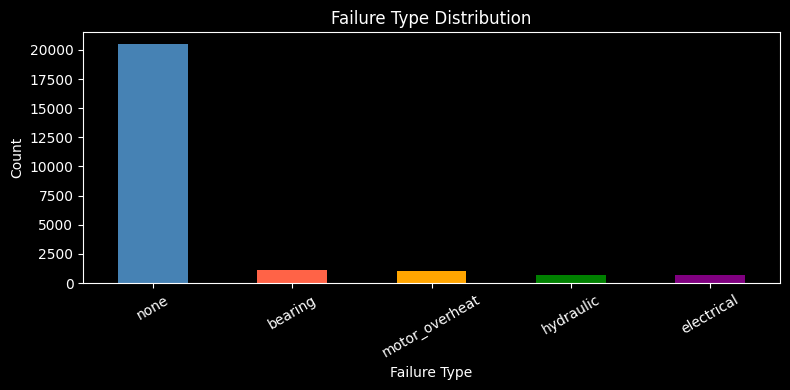

In [3]:
# ============================================================
# CELL 3 — Class Balance (Failure Types)
# ============================================================
counts = df['failure_type'].value_counts()
print(counts)
print(f"\nClass imbalance: {counts['none']/len(df)*100:.1f}% are no-failure")

counts.plot(kind='bar', color=['steelblue','tomato','orange','green','purple'],
            figsize=(8,4))
plt.title("Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [4]:
# ============================================================
# CELL 4 — Clean & Encode
# ============================================================
numeric_cols = ['vibration_rms','temperature_motor','current_phase_avg',
                'pressure_level','rpm']

# Forward fill per machine then global mean
df[numeric_cols] = df.groupby('machine_id')[numeric_cols].transform(
    lambda x: x.ffill().fillna(x.mean())
)

df['operating_mode_enc'] = df['operating_mode'].map({'idle':0,'normal':1,'peak':2})
df['failure_label'] = df['failure_type'].map(
    {'none':0,'hydraulic':1,'bearing':2,'motor_overheat':3,'electrical':4}
)
print("Cleaned. Remaining nulls:", df.isnull().sum().sum())

Cleaned. Remaining nulls: 0


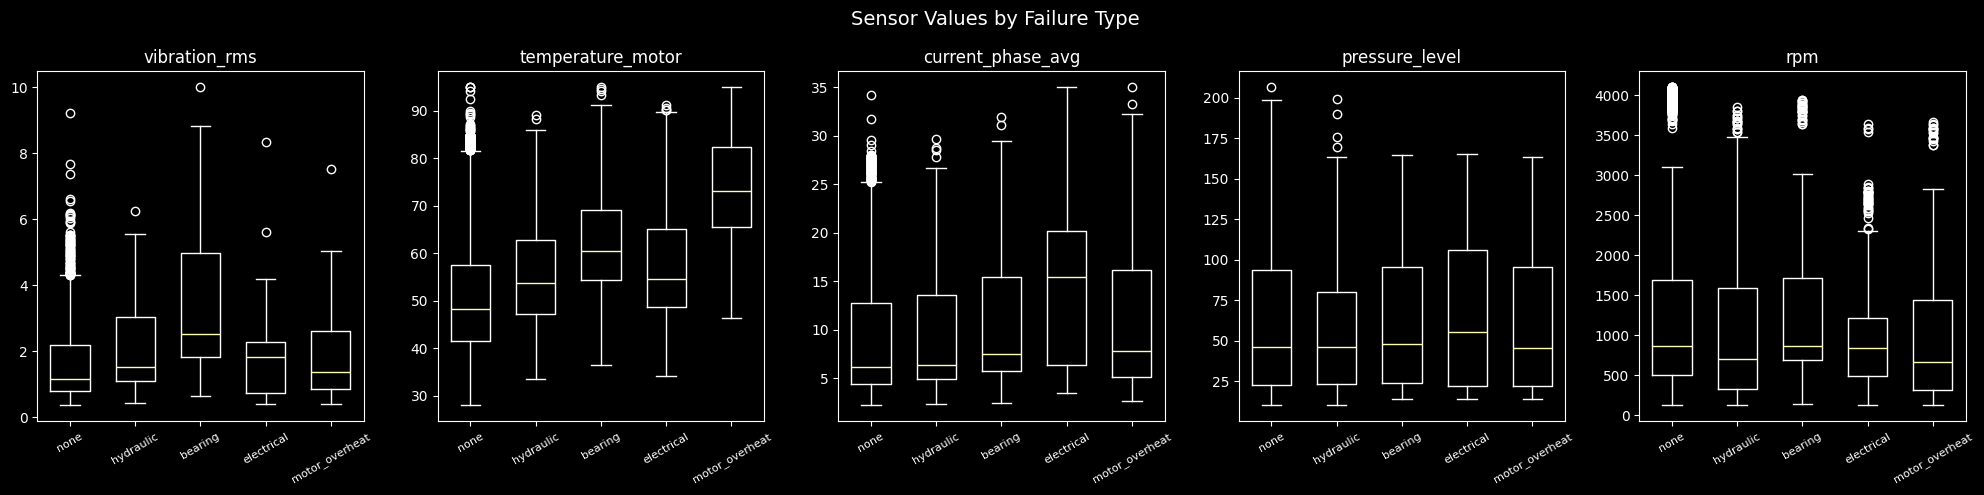

In [5]:
# ============================================================
# CELL 5 — Sensor Distributions per Failure Type
# ============================================================
features = ['vibration_rms','temperature_motor','current_phase_avg',
            'pressure_level','rpm']

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, feat in zip(axes, features):
    for ft in df['failure_type'].unique():
        subset = df[df['failure_type']==ft][feat].dropna()
        ax.boxplot(subset, positions=[list(df['failure_type'].unique()).index(ft)],
                   widths=0.6)
    ax.set_title(feat)
    ax.set_xticks(range(5))
    ax.set_xticklabels(df['failure_type'].unique(), rotation=30, fontsize=8)
plt.suptitle("Sensor Values by Failure Type", fontsize=14)
plt.tight_layout()
plt.show()

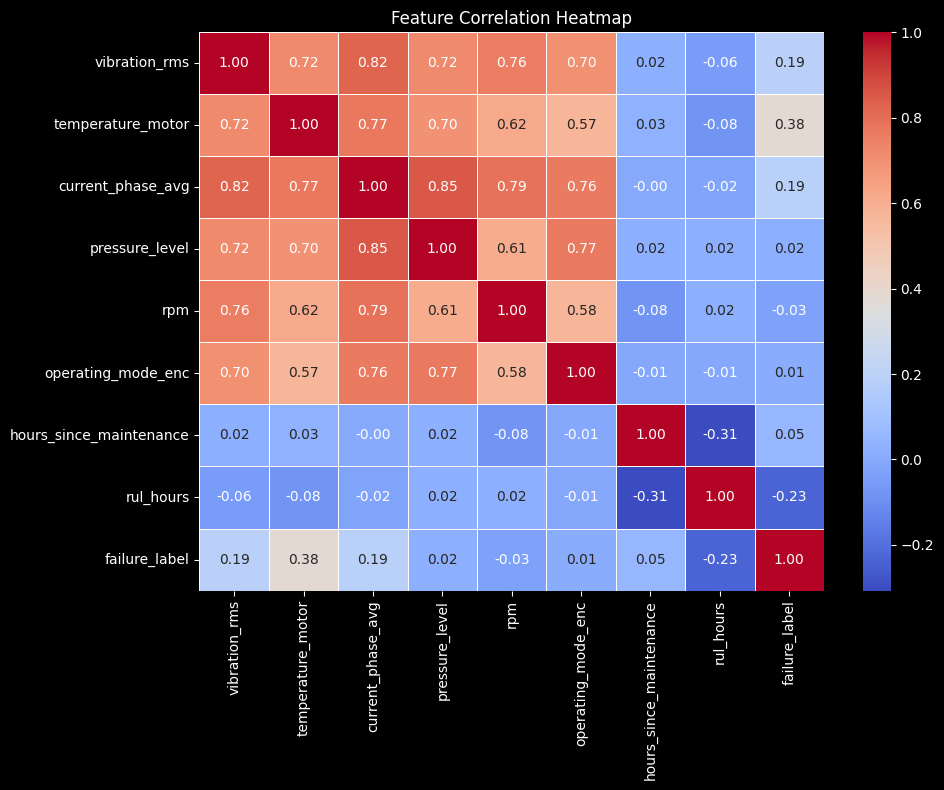


Correlation with failure_label:
failure_label              1.000000
temperature_motor          0.382733
vibration_rms              0.188902
current_phase_avg          0.187599
hours_since_maintenance    0.052342
pressure_level             0.023265
operating_mode_enc         0.006568
rpm                       -0.033043
rul_hours                 -0.231959
Name: failure_label, dtype: float64


In [6]:
# ============================================================
# CELL 6 — Correlation Heatmap
# ============================================================
corr_cols = ['vibration_rms','temperature_motor','current_phase_avg',
             'pressure_level','rpm','operating_mode_enc',
             'hours_since_maintenance','rul_hours','failure_label']

corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nCorrelation with failure_label:")
print(corr['failure_label'].sort_values(ascending=False))

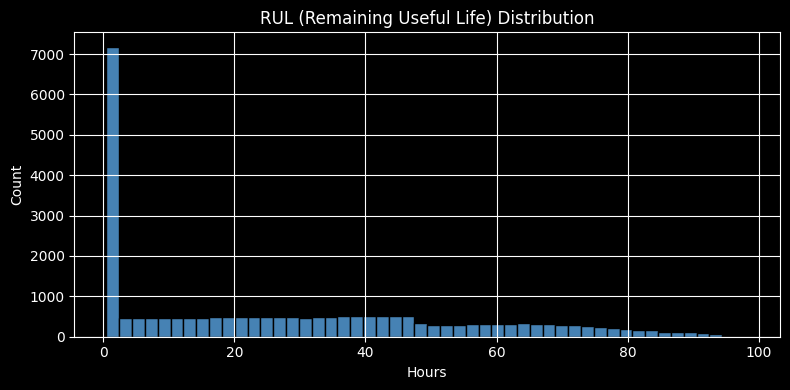

In [7]:
# ============================================================
# CELL 7 — RUL Distribution
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"E:\DOCUMENTS\UNIVERSITÄT STUTTGART\SEMESTER COURSES\7. WiSe 2025-26\RP\Datasets\predictive_maintenance_v03.csv")
plt.figure(figsize=(8,4))
df["rul_hours"].dropna().hist(bins=50, color="steelblue", edgecolor="black")
plt.title("RUL (Remaining Useful Life) Distribution")
plt.xlabel("Hours")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

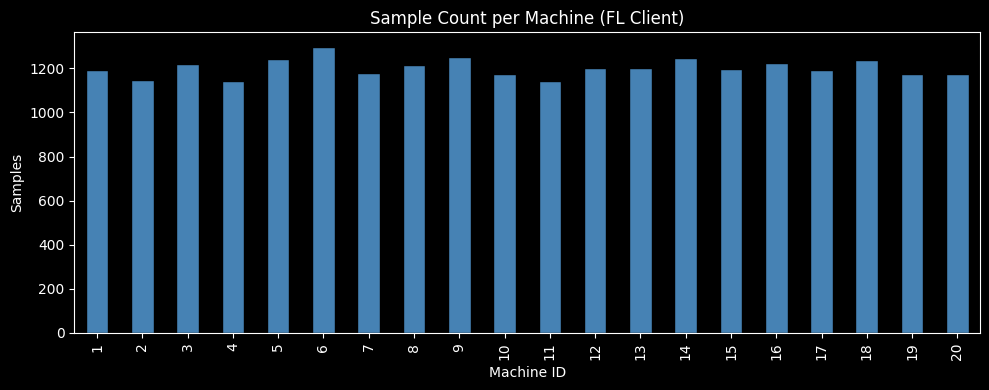

In [8]:
# ============================================================
# CELL 8 — Samples per Machine (FL clients)
# ============================================================
df['machine_id'].value_counts().sort_index().plot(kind='bar', figsize=(10,4),
    color='steelblue', edgecolor='black')
plt.title("Sample Count per Machine (FL Client)")
plt.xlabel("Machine ID")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()

                precision    recall  f1-score   support

          none       0.85      1.00      0.92      4043
     hydraulic       0.00      0.00      0.00       187
       bearing       0.00      0.00      0.00       172
motor_overheat       1.00      0.11      0.20       345
    electrical       0.00      0.00      0.00        62

      accuracy                           0.85      4809
     macro avg       0.37      0.22      0.22      4809
  weighted avg       0.78      0.85      0.79      4809



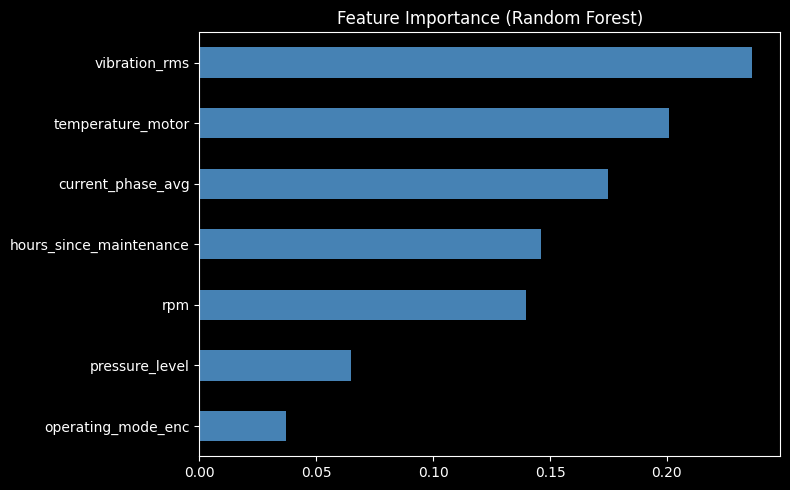

In [9]:
# ============================================================
# CELL 9 — Feature Importance via Random Forest
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

if 'operating_mode_enc' not in df.columns:
    df['operating_mode_enc'] = df['operating_mode'].map({'idle': 0, 'normal': 1, 'peak': 2}).fillna(-1).astype(int)

if 'failure_label' not in df.columns:
    df['failure_label'] = df['failure_type'].map(
        {'none': 0, 'hydraulic': 1, 'bearing': 2, 'motor_overheat': 3, 'electrical': 4}
    ).fillna(0).astype(int)

feature_cols = ['vibration_rms','temperature_motor','current_phase_avg',
                'pressure_level','rpm','operating_mode_enc',
                'hours_since_maintenance']

X = df[feature_cols].copy().fillna(0)
y = df['failure_label'].astype(int)
cut = int(len(X)*0.8)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

clf = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
clf.fit(X_scaled[:cut], y[:cut])
y_pred = clf.predict(X_scaled[cut:])

labels = ['none','hydraulic','bearing','motor_overheat','electrical']
print(classification_report(y[cut:], y_pred, labels=[0, 1, 2, 3, 4], target_names=labels, zero_division=0))

importances = pd.Series(clf.feature_importances_, index=feature_cols)
importances.sort_values().plot(kind='barh', figsize=(8,5), color='steelblue')
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

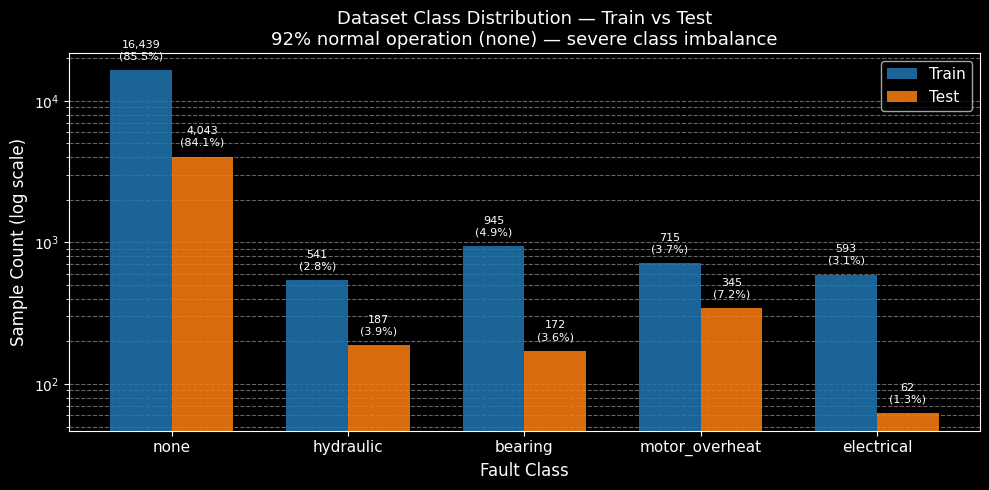

✅ Saved → outputs/plots/class_distribution.png


In [14]:
# Cell — Dataset Class Distribution
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── 1. Count from your actual DataFrame ──────────────────────
label_col = 'fault_type'   # change to your actual column name
class_order = ['none', 'hydraulic', 'bearing', 'motor_overheat', 'electrical']

# Use the correct target column from this notebook
if label_col not in df.columns:
    label_col = 'failure_type'

# Create train/test split if not already defined
if 'train_df' not in globals() or 'test_df' not in globals():
    split_idx = int(len(df) * 0.8)
    train_df = df.iloc[:split_idx].copy()
    test_df = df.iloc[split_idx:].copy()

train_counts = [train_df[label_col].value_counts().get(c, 0) for c in class_order]
test_counts  = [test_df[label_col].value_counts().get(c, 0)  for c in class_order]

total_train  = sum(train_counts)
total_test   = sum(test_counts)

# ── 2. Plot ───────────────────────────────────────────────────
x     = np.arange(len(class_order))
width = 0.35
colors_train = '#1f77b4'
colors_test  = '#ff7f0e'

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(x - width/2, train_counts, width, label='Train',
               color=colors_train, alpha=0.85)
bars2 = ax.bar(x + width/2, test_counts,  width, label='Test',
               color=colors_test,  alpha=0.85)

# Annotate each bar with count + %
for bar, count, total in zip(bars1, train_counts, [total_train]*5):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.15,
            f'{count:,}\n({count/total*100:.1f}%)',
            ha='center', va='bottom', fontsize=8)

for bar, count, total in zip(bars2, test_counts, [total_test]*5):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.15,
            f'{count:,}\n({count/total*100:.1f}%)',
            ha='center', va='bottom', fontsize=8)

ax.set_yscale('log')                          # log scale — makes rare classes visible
ax.set_xlabel('Fault Class',  fontsize=12)
ax.set_ylabel('Sample Count (log scale)', fontsize=12)
ax.set_title('Dataset Class Distribution — Train vs Test\n'
             '92% normal operation (none) — severe class imbalance', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(class_order, fontsize=11)
ax.legend(fontsize=11)
ax.yaxis.grid(True, which='both', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
out_path = Path("outputs/plots/class_distribution.png")
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved → outputs/plots/class_distribution.png")